----
# Laboratorium 3 - Zespolony szereg Fouriera
----
Materiały dydaktyczne przeznaczone są wyłącznie dla studentów wydziału Informatyki i Telekomunikacji Politechniki Poznański

----
## 0 Zagadnienia do opanowania przed zajęciami:
---- 
### 0.1 Wyznaczanie współczynników zespolonego szeregu Fouriera
### 0.2 Zbieżność szeregu Fouriera
### 0.3 Efekt Gibbsa
*Literatura:*
- wykłady i ćwiczenia z przedmiotu Teoria Sygnałów
- R. Gabel, R. Robeerts, Sygnały i systemy liniowe, str. 181-197
- J. Izydorczyk, G. Płonka, G. Tyma, Teoria sygnałów, str. 1-19

### 0.4 Używanie języka Python, szczególnie biblioteki *sympy* w zakresie operacji całkowania oraz używania funkcji ekspotencjalnej, oraz funkcjonalności lambdify i Piecewise. Obsługa sympy w zakresie definiowania zmiennych i funkcji (sympy.symbol). 
- https://docs.sympy.org/latest/modules/integrals/integrals.html
- https://docs.sympy.org/latest/modules/functions/elementary.html#sympy-functions-elementary-exponential
- https://docs.sympy.org/latest/modules/utilities/lambdify.html
- https://docs.sympy.org/latest/modules/functions/elementary.html

### 0.5 Określanie wzoru funkcji w zadanym przedziale na podstawie jej wykresu.

## 🧭 Jak czytać ten notatnik
To Twój notatnik – kod, który już był, został zostawiony, ale ma **komentarz przy każdej linijce** i kilka poprawek (każda opisana w sekcji „🛠 Poprawki”). Do każdego zadania doszły sekcje **📘 Teoria**, **🔧 Składnia**, **💡 Wyjaśnienie wyniku** / **✅ Wnioski**. Zadania 5 (własna rekonstrukcja) i 6 są dopisane od zera. Na końcu **📝 ściąga**.

### 🔧 Składnia – użyte funkcje

- `import ipywidgets` – biblioteka interaktywnych kontrolek w Jupyterze (suwaki, przyciski). Używa jej moduł `xInteractiveFourier` w zadaniu 5.
- Reszta jak w poprzednich labach: `sympy` (symbolicznie), `numpy` (numerycznie), `matplotlib.pyplot` (wykresy).

In [1]:
%matplotlib inline
import sympy                       # obliczenia symboliczne: całki, wzory
import numpy as np                 # obliczenia numeryczne na wektorach
import matplotlib.pyplot as plt    # wykresy
import ipywidgets                  # interaktywne kontrolki (suwaki) – używa ich xInteractiveFourier

----
## 1. Określanie wzorów funkcji
----
### Zadanie: Na podstawie poniższych wykresów określ wzór funkcji w odpowiednim zakresie wartości
<table><tr><td>
Funkcja A
<br>
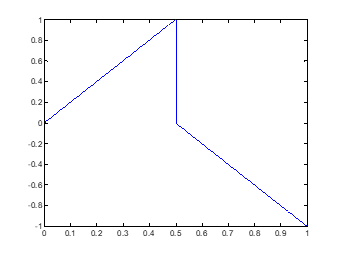
</td><td>
Funkcja B
<br>
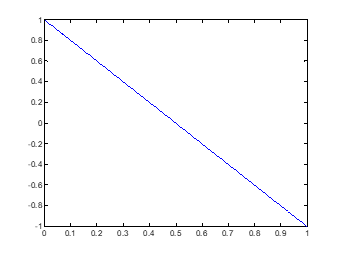
</td><td>
Funkcja C
<br>
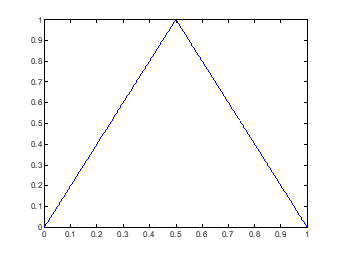
</td></tr><tr><td>
Funkcja D
<br>
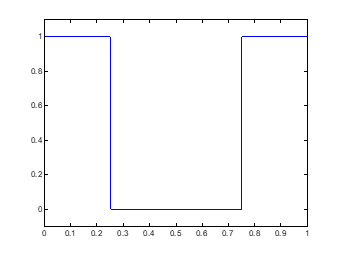
</td><td>
Funkcja E
<br>
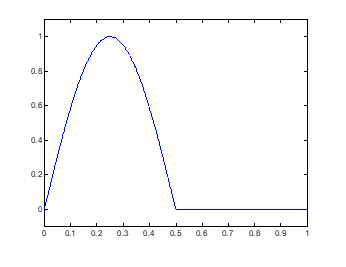
</td><td>
Funkcja F
<br>
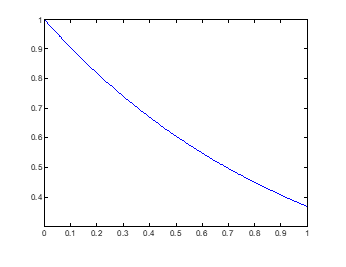
</td></tr>

### 📘 Teoria

Każdy wykres to **jeden okres** $T=1$ (oś pozioma od 0 do 1). Funkcja okresowa powtarza ten kawałek w nieskończoność: $f(t+T)=f(t)$.

**Jak odczytać wzór odcinka prostej:** prosta $y=a\,t+b$, gdzie
$$a=\frac{\Delta y}{\Delta t}=\frac{y_2-y_1}{t_2-t_1}\quad\text{(nachylenie)},\qquad b = y_1 - a\,t_1.$$
Np. funkcja A na $[0{,}5;\,1]$: punkty $(0{,}5;\,0)$ i $(1;\,-1)$ → $a=\frac{-1-0}{1-0{,}5}=-2$, $b=0-(-2)(0{,}5)=1$ → $y=-2t+1$.

Żeby wzory działały **dla dowolnego okresu T**, zamiast $t$ piszemy $\frac{t}{T}$ (czyli „ułamek okresu”), a granice przedziałów to $\frac{T}{2}, \frac{T}{4}, \dots$

| Funkcja | Wzór (jak na tablicy, T = 1) | Wzór zależny od T |
|---|---|---|
| **A** | $2t$ na $[0;\,0{,}5)$, $\ -2t+1$ na $[0{,}5;\,1)$ | $\frac{2t}{T}$ dla $t<\frac T2$, $\ -\frac{2t}{T}+1$ dalej |
| **B** | $-2t+1$ na $[0;\,1)$ | $-\frac{2t}{T}+1$ |
| **C** | $2t$ na $[0;\,0{,}5)$, $\ -2t+2$ na $[0{,}5;\,1)$ | $\frac{2t}{T}$, $\ -\frac{2t}{T}+2$ |
| **D** | $1$ na $[0;\,0{,}25)$, $\ 0$ na $[0{,}25;\,0{,}75)$, $\ 1$ na $[0{,}75;\,1)$ | granice $\frac T4$, $\frac{3T}{4}$ |
| **E** | $\sin(2\pi t)$ na $[0;\,0{,}5)$, $\ 0$ na $[0{,}5;\,1)$ | $\sin\frac{2\pi t}{T}$ dla $t<\frac T2$ |
| **F** | $e^{-t}$ na $[0;\,1)$ | $e^{-t/T}$ |

Skąd E i F: garb E ma zera w 0 i 0,5 i max 1 w 0,25 – to połówka sinusa o okresie 1. Dla F wartość na końcu to $0{,}368=e^{-1}$, więc to $e^{-t}$.

----
## 2. Wyliczanie próbek funkcji
----
### Zadanie: Zdefiniuj wektor zawierający próbki jednego okresu badanej funkcji (składający się z przynajmniej 200 elementów). Wyświetl wyznaczone próbki na wykresie (matlplotlib). 
Definicje funkcji uzależnij od `T`.  
Podpowiedź: użyj `sympy.Piecewise` do zdefiniowania funkcji oraz `sympy.lambdify` 


### 🔧 Składnia – użyte funkcje

| Funkcja | Co robi | Przykład |
|---|---|---|
| `sympy.Symbol('t', real=True)` | zmienna symboliczna `t` | |
| `sympy.Piecewise((wyr1, war1), (wyr2, war2), ...)` | **funkcja przedziałami**: bierze **pierwsze** wyrażenie, którego warunek jest prawdziwy. Ostatni warunek to zwykle `True` = „w pozostałych przypadkach” | `Piecewise((1, t < 0.25), (0, t < 0.75), (1, True))` → 1, potem 0, potem 1 |
| `sympy.sin`, `sympy.exp`, `sympy.pi` | sinus, $e^x$, $\pi$ w wersji symbolicznej (do wzorów sympy **nie** używamy `np.sin`!) | |
| `sympy.lambdify(t, wyrażenie, 'numpy')` | zamienia wzór sympy na **zwykłą funkcję Pythona** liczoną przez numpy; potem wywołujemy ją na liczbach: `f(0.3)` | `f = sympy.lambdify(t, t**2, 'numpy'); f(3)` → 9 |
| `[f(x) for x in tt]` | **list comprehension** – liczy `f` dla każdego `x` z wektora `tt` osobno i zbiera wyniki w listę | |
| `np.array(lista)` | zamienia listę na wektor numpy | |
| `{'A': fA, ...}` | **słownik**: klucz → wartość; `AllFuns['A']` zwraca `fA` | |
| `plt.subplot(2, 3, i+1)` | siatka 2 wiersze × 3 kolumny, pole nr `i+1` (numeracja od 1) | |

### 🛠 Poprawki w Twoim kodzie
1. **fE:** było `sympy.sin(2*sympy.pi*t)/T` – dzielenie przez T było **poza** sinusem. Poprawnie: `sympy.sin(2*sympy.pi*t/T)` (przy T=1 wynik ten sam, ale przy innym T wzór byłby zły).
2. **AllFuns:** było `'E': fF` – literówka, E wskazywało na funkcję F. Poprawione na `'E': fE`.
3. **Próbkowanie:** `sympy.lambdify(...)(tt)` dla funkcji, której jedna gałąź jest stałą (np. `(0, True)`), czasem zwraca **pojedynczą liczbę** zamiast wektora 200 wartości → błąd `x and y must have same first dimension`. Dlatego liczymy punkt po punkcie: `np.array([f(x) for x in tt])` – działa zawsze.
4. Do wykresów dodane tytuły.

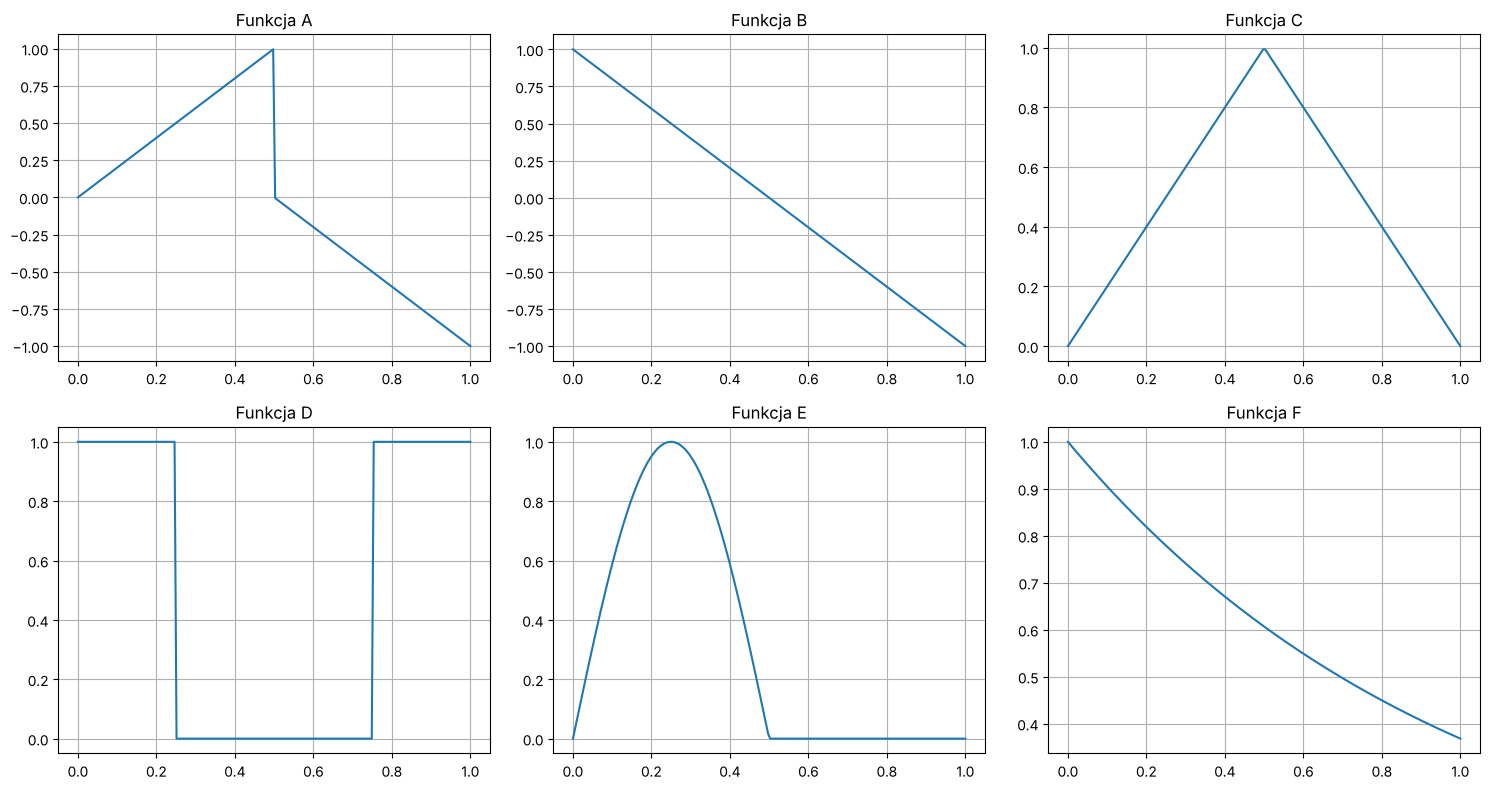

In [2]:
import sympy
import numpy as np
import matplotlib.pyplot as plt

#declare symbolic variable t (time) and period (T=1)
t = sympy.Symbol('t', real = 'True', nonzero = 'True')    # zmienna symboliczna t (czas)
T = 1                                                     # okres funkcji

fA = sympy.Piecewise((2*t/T, t < T/2), (-2*t/T + 1, True))          # A: rampa w górę, skok, rampa w dół
fB = -2*t/T + 1                                                      # B: piła malejąca od 1 do -1
fC = sympy.Piecewise((2*t/T, t < T/2), (-2*t/T + 2, True))          # C: trójkąt
fD = sympy.Piecewise((1, t < T/4), (0, t < 3*T/4), (1, True))       # D: prostokąt (1, 0, 1)
fE = sympy.Piecewise((sympy.sin(2*sympy.pi*t/T), t < T/2), (0, True))   # E: połówka sinusa, potem 0  (POPRAWIONE: /T w środku sin)
fF = sympy.exp(-t/T)                                                 # F: eksponenta malejąca

AllFuns = {'A':fA,'B':fB,'C':fC,'D':fD,'E':fE,'F':fF}   # słownik nazwa → funkcja  (POPRAWIONE: 'E':fE)

currFun = fE                                   # funkcja wybrana do dalszych zadań
NumberOfSamples = 200                          # liczba próbek jednego okresu (zadanie: min. 200)
tt = np.linspace(0,T,NumberOfSamples)          # 200 chwil czasu od 0 do T

f = sympy.lambdify(t,currFun,'numpy')          # wzór sympy → zwykła funkcja Pythona
Samples = np.array([f(x) for x in tt])         # wartość w każdej chwili osobno → wektor 200 próbek

funkcje = [fA,fB,fC,fD,fE,fF]                  # lista wszystkich funkcji
nazwy = ['A','B','C','D','E','F']              # i ich nazw (do tytułów)

plt.figure(figsize=(15,8))                     # jedno duże okno

for i in range (6):                            # i = 0..5 – po kolei każda funkcja
  f = sympy.lambdify(t,funkcje[i],'numpy')     # i-ta funkcja jako funkcja Pythona
  y = [f(x) for x in tt]                       # jej próbki
  plt.subplot(2,3,i+1)                         # pole i+1 w siatce 2×3
  plt.plot(tt,y)                               # wykres
  plt.title('Funkcja ' + nazwy[i])             # tytuł
  plt.grid()                                   # siatka

plt.tight_layout()                             # rozsunięcie wykresów
plt.show()                                     # wyświetlenie

### 💡 Wyjaśnienie wyniku

Sześć wykresów wygląda dokładnie jak obrazki z zadania 1 – wzory są dobrze odczytane. `Samples` to wektor 200 próbek funkcji `currFun` – przyda się w zadaniu 5.

----
## 3. Wyznaczanie współczynników szeregu Fouriera (analityczne)
----
### Zadanie: Na podstawie wyznaczonych wzorów funkcji znajdź rozwinięcie funkcji w szereg Fouriera. Skorzystaj z biblioteki sympy w środowisku Python. 
- Jakie założenie należy przyjąć przy wyznaczaniu współczynników szeregu Fouriera ?

$ f(t) = \sum_{k=-\infty}^{\infty} F_k e^{j k {{2 \pi } \over T } t} \text{   for:   } k \in \mathbb{C} $

$ F_0 = { 1 \over T } \int\limits_{-{T \over 2}}^{{T \over 2}}f(t)dt $

$ F_k = { 1 \over T } \int\limits_{-{T \over 2}}^{{T \over 2}} f(t) e^{-jkt {2\pi \over T}} dt \text{   for:   } k \in \mathbb{C}, k \neq 0 $

Podpowiedź: funkcje `sympy.exp`, `sympy.simplify`, `sympy.integrate`

### 📘 Teoria

**Idea szeregu Fouriera:** każdy (rozsądny) sygnał okresowy da się zapisać jako **sumę drgań harmonicznych** o częstotliwościach $0, \omega, 2\omega, 3\omega, \dots$, gdzie $\omega=\frac{2\pi}{T}$:
$$f(t)=\sum_{k=-\infty}^{\infty}F_k\,e^{jk\omega t}$$
- $e^{jk\omega t}=\cos k\omega t + j\sin k\omega t$ to „obracający się wektor” – drganie o częstotliwości $k\omega$,
- $F_k$ (liczba **zespolona**) mówi, **ile** jest tego drgania ($|F_k|$ – amplituda) i **jak jest przesunięte** ($\arg F_k$ – faza).

**Skąd wzór na $F_k$?** Mnożymy sygnał przez $e^{-jk\omega t}$ i uśredniamy po okresie. Wszystkie składowe poza $k$-tą dają w całce 0 (są „ortogonalne”), więc zostaje tylko $F_k$:
$$F_k=\frac{1}{T}\int_{0}^{T} f(t)\,e^{-jk\omega t}\,dt,\qquad F_0=\frac1T\int_0^T f(t)\,dt\ \ \text{(wartość średnia)}$$

**Dlaczego całkujemy od 0 do T, a nie od $-\frac T2$ do $\frac T2$?** Dla funkcji okresowej całka po **dowolnym** przedziale długości $T$ daje to samo. Nasze wzory są zdefiniowane na $[0,T)$, więc tak jest wygodniej.

**Dlaczego $F_0$ osobno?** W ogólnym wzorze na $F_k$ po scałkowaniu pojawia się $k$ w mianowniku – dla $k=0$ byłoby dzielenie przez zero.

**Dla sygnałów rzeczywistych** $F_{-k}=F_k^*$ (sprzężenie), więc wystarczy liczyć $k>0$.

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `k = sympy.Symbol('k', integer=True, positive=True)` | symbol `k` z założeniem: **dodatnia liczba całkowita**. Dzięki temu sympy wie, że $e^{-j2\pi k}=1$ i $e^{-j\pi k}=(-1)^k$, i upraszcza wynik |
| `sympy.I` | jednostka urojona $j$ |
| `sympy.exp(-sympy.I*k*2*sympy.pi/T*t)` | jądro $e^{-jk\frac{2\pi}{T}t}$ |
| `sympy.integrate(f, (t, a, b))` | całka oznaczona po `t` od `a` do `b` |
| `wyrażenie.simplify()` | uproszczenie wzoru |
| `def f(..., DisplayCoeffs=True)` | **argument domyślny**: jeśli go nie podamy, ma wartość `True` |
| `return F0, Fk` | funkcja zwraca **dwie** wartości naraz; odbieramy je `F0, Fk = ...` |
| `display('F0 =', F0)` | ładne wyświetlenie wzoru |

In [3]:
currFun = fB                                   # funkcja, dla której liczymy współczynniki

k = sympy.Symbol('k', real = 'True', nonzero=True, positive=True, integer=True)   # numer harmonicznej k = 1, 2, 3, ...

def determineFourierCoefficients(Function, RangeBeg, RangeEnd, DisplayCoeffs=True):
    kernel = sympy.exp(-sympy.I * k * 2*sympy.pi/T * t)        # jądro e^{-jk(2π/T)t}

    #determine F0
    F0 = 1/T * sympy.integrate(Function, (t, RangeBeg, RangeEnd))            # F0 = (1/T)∫f(t)dt – wartość średnia

    #determine Fk
    Fk = 1/T * sympy.integrate(Function * kernel, (t, RangeBeg, RangeEnd))   # Fk = (1/T)∫f(t)·e^{-jkωt}dt

    if DisplayCoeffs:                          # wyświetlamy tylko jeśli o to poproszono
        display('F0 =', F0.simplify())         # uproszczony wzór na F0
        display('Fk =', Fk.simplify())         # uproszczony wzór na Fk

    return F0, Fk                              # zwracamy oba wyrażenia

F0, Fk = determineFourierCoefficients(currFun, 0, T)     # całkujemy po jednym okresie [0, T]

'F0 ='

0

'Fk ='

-1.0*I/(pi*k)

Ta sama funkcja dla **wszystkich** sześciu sygnałów (komórka dodana – pętla po słowniku):

In [4]:
for nazwa, fun in AllFuns.items():                     # .items() daje pary (klucz, wartość)
    print('------ Funkcja', nazwa)
    determineFourierCoefficients(fun, 0, T)            # liczy i wyświetla F0 i Fk

------ Funkcja A


'F0 ='

0

'Fk ='

(-1)**k*((-1)**(k + 1)*(0.5*I*pi*k + 1.0) + 0.5*I*pi*k + 1.0)/(pi**2*k**2)

------ Funkcja B


... (20 outputs left out)

'F0 ='

1.0 - 1.0*exp(-1)

'Fk ='

2.0*I*(1 - E)*exp(-1)/(4.0*pi*k - 2.0*I)

### ✅ Wnioski / odpowiedzi na pytania

**Jakie założenie należy przyjąć?**
1. Funkcja jest **okresowa** z okresem $T$ – narysowany kawałek powtarza się w nieskończoność. Tylko wtedy ma sens rozkład na harmoniczne $k\omega$.
2. Funkcja spełnia **warunki Dirichleta**:
   - jest bezwzględnie całkowalna na okresie: $\int_0^T|f(t)|\,dt<\infty$,
   - ma skończoną liczbę ekstremów w okresie,
   - ma skończoną liczbę nieciągłości (skoków skończonej wysokości).

Wtedy szereg jest zbieżny do $f(t)$ w punktach ciągłości, a **w punkcie skoku do średniej** $\frac{f(t^-)+f(t^+)}{2}$ (np. dla D w $t=\frac T4$ szereg da $0{,}5$).

**Przykład – funkcja B:** $F_0=0$ (średnia piły to 0), $F_k=-\frac{j}{\pi k}$ – czysto urojone, bo B jest nieparzysta względem środka okresu.

----
## 4. Wyznaczanie wartości pierwszych 10 współczynników szeregu Fouriera
---- 
Zadanie: Wygeneruj wektor zawierający 10 pierwszych współczynników szeregu Fouriera

Podpowiedz: wykorzystaj funkcje z poprzednich zadań, pamiętaj że współczynniki zespolonego szeregu Fouriera należą do zbioru liczb **ZESPOLONYCH** (użyj odpowiedniego typu danych - `np.cdouble`)

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `np.zeros(10, dtype=np.cdouble)` | wektor 10 zer typu **complex double** (liczby zespolone). Zwykły `float` zgubiłby część urojoną (a dla B **cały** współczynnik jest urojony!) |
| `Fk.subs(k, n)` | **podstawienie**: w miejsce symbolu `k` wstawia liczbę `n` |
| `sympy.N(wyrażenie)` | liczy przybliżoną wartość liczbową (np. $\frac{1}{\pi}$ → `0.318...`) |
| `complex(...)` | zamienia wynik sympy na zwykłą liczbę zespoloną Pythona, którą można wpisać do tablicy numpy |
| `np.set_printoptions(precision=4, suppress=True)` | ładniejsze wypisywanie: 4 miejsca po przecinku, bez notacji `1e-22` |

### 🛠 Poprawka
W wyniku pojawiały się śmieci typu `4.2e-22+0.318j` – część rzeczywista to tylko **błąd numeryczny** (powinno być 0). Dodane `np.set_printoptions(suppress=True)`, które wyświetla takie liczby jako `0`.

In [5]:
Coeffs = np.zeros(10, dtype=np.cdouble)        # miejsce na 10 współczynników ZESPOLONYCH: F0..F9

Coeffs[0] = complex(sympy.N(F0))               # F0 – liczony osobno (wzór z zadania 3)
for n in range(1,10):                          # n = 1..9
  Coeffs[n] = complex(sympy.N(Fk.subs(k,n)))   # podstawiamy k = n do wzoru na Fk i liczymy wartość

np.set_printoptions(precision=4, suppress=True)   # 4 miejsca po przecinku, bez śmieci 1e-22
print(Coeffs)                                  # wypisanie wektora
print('|Fk| =', np.abs(Coeffs))                # amplitudy (moduły)

[0.+0.j     0.-0.3183j 0.-0.1592j 0.-0.1061j 0.-0.0796j 0.-0.0637j
 0.-0.0531j 0.-0.0455j 0.-0.0398j 0.-0.0354j]
|Fk| = [0.     0.3183 0.1592 0.1061 0.0796 0.0637 0.0531 0.0455 0.0398 0.0354]


### 💡 Wyjaśnienie wyniku

Dla **B**: $F_0=0$, $F_1\approx-0{,}318j$, $F_2\approx-0{,}159j$, … – czyli $-\frac{j}{\pi k}$: maleją jak $\frac1k$. Wolne malenie to znak, że sygnał ma **skok** (piła skacze z $-1$ na $1$ na granicy okresów). Dla funkcji ciągłych (np. trójkąt C) współczynniki maleją szybciej, jak $\frac{1}{k^2}$.

----
## 5. Rekonstrukcja sygnału
----
Wykorzystując klasę `xInteractiveFourier` oraz metody `xInteractiveFourier.complexFourierSeries` oraz `xInteractiveFourier.createDemo` zaobserwuj proces proces kolejnego przybliżania sygnału sumą początkowych wyrazów przebiegu. Zwróć uwagę na błędy aproksymacji występujące w ewentualnych punktach nieciągłości oraz przeanalizuj zależność błędu średniokwadratowego i maksymalnego od liczby składników szeregu. 

Funkcja `xInteractiveFourier.complexFourierSeries` jako argumenty przyjmuje: F0 - wartość współczynnika F0, Fk - wyrażenie na współczynniki fk, Samples - próbki aproksymowanej funkcji, rangeStart - minimalny argument aproksymowanej funkcji, rangeStop - maksymalny argument aproksymowanej funkcji. 

Następnie sprawdz, jak wyglądają przebiegi aproksymowane z uzyciem współczynników szeregu, które niosą jedynie informacje o amlitudzie $abs(fk)$ oraz zwpółczynników które niosą tylko informację o fazie $e^{j\phi}$. W tym celu dodaj "mag" lub "phase" jako dodatkowy argument funkcji `complexFourierSeries`.

### 📘 Teoria

**Rekonstrukcja** = suma **skończonej** liczby wyrazów szeregu (suma częściowa):
$$f_N(t)=F_0+\sum_{k=1}^{N}\left(F_k e^{jk\omega t}+F_k^{*} e^{-jk\omega t}\right)=F_0+\sum_{k=1}^{N}2|F_k|\cos(k\omega t+\varphi_k)$$
Im większe $N$, tym bliżej oryginału.

**Efekt Gibbsa:** w pobliżu skoku suma częściowa „przestrzeliwuje” o ok. **9% wysokości skoku** i oscyluje. Ze wzrostem $N$ oscylacje się **zwężają** (zbliżają do skoku), ale ich **wysokość nie maleje**.

**Błędy:**
- średniokwadratowy $\text{MSE}=\frac1N\sum (f-f_N)^2$ – maleje do zera (z tw. Parsevala to suma $|F_k|^2$ pominiętych wyrazów),
- maksymalny $\max|f-f_N|$ – przy skokach **nie maleje do zera** (Gibbs + w samym punkcie skoku szereg daje średnią).

**Tylko amplituda / tylko faza:**
- `mag` – zamiast $F_k$ bierzemy $|F_k|$ (wszystkie fazy = 0),
- `phase` – zamiast $F_k$ bierzemy $e^{j\varphi_k}$ (wszystkie amplitudy = 1).

### 🔧 Składnia – użyte funkcje

**Moduł prowadzącego** (plik `xInteractiveFourier.py` musi leżeć w tym samym folderze co notatnik):
- `xInteractiveFourier(MaxNumCoeffs)` – tworzy obiekt demonstracji z maks. liczbą współczynników,
- `.complexFourierSeries(F0, Fk, Samples, start, stop[, "mag"/"phase"])` – podaje mu współczynniki i próbki oryginału,
- `.createDemo(FigSize)` – zwraca interaktywny wykres z suwakiem liczby wyrazów.

**Własna wersja (dodana niżej, gdyby moduł nie działał):**
| Składnia | Co robi |
|---|---|
| `np.exp(1j*n*w*tt)` | $e^{jn\omega t}$ dla całego wektora czasu; `1j` to $j$ w numpy |
| `np.conj(c)` | sprzężenie zespolone $c^*$ |
| `np.abs(c)`, `np.angle(c)` | moduł i faza liczby zespolonej |
| `y.real` | część rzeczywista (urojona jest ≈ 0, tylko błędy zaokrągleń) |
| `np.mean((a-b)**2)` | błąd średniokwadratowy |
| `plt.semilogy(x, y)` | wykres z **logarytmiczną osią y** – dobrze widać malejący błąd |

In [6]:
FigSize      = (16, 10)    # rozmiar okna demonstracji
MaxNumCoeffs = 20          # max num coeff used for demo – maksymalna liczba wyrazów szeregu

currFun = fD                                                       # funkcja do rekonstrukcji (D ma skoki → widać Gibbsa)
F0, Fk  = determineFourierCoefficients(currFun, 0, T, DisplayCoeffs=False)   # współczynniki bez wyświetlania
f = sympy.lambdify(t, currFun, 'numpy')                            # wzór → funkcja Pythona
Samples = np.array([f(x) for x in np.linspace(0, T, NumberOfSamples)])        # próbki oryginału

try:                                                               # spróbuj użyć modułu prowadzącego...
    from xInteractiveFourier import *                              # wczytanie klasy z pliku xInteractiveFourier.py
    InteractiveFourier = xInteractiveFourier(MaxNumCoeffs)         # obiekt demonstracji
    InteractiveFourier.complexFourierSeries(F0, Fk, Samples, 0, T) # pełne współczynniki
    # InteractiveFourier.complexFourierSeries(F0, Fk, Samples, 0, T, "mag")    # tylko amplituda
    # InteractiveFourier.complexFourierSeries(F0, Fk, Samples, 0, T, "phase")  # tylko faza
    Demo = InteractiveFourier.createDemo(FigSize)                  # interaktywny wykres z suwakiem
    display(Demo)                                                  # wyświetlenie
except ImportError:                                                # ...a jeśli pliku nie ma:
    print('Brak pliku xInteractiveFourier.py – użyj własnej wersji z następnej komórki.')

Brak pliku xInteractiveFourier.py – użyj własnej wersji z następnej komórki.


#### Własna rekonstrukcja (komórka dodana)

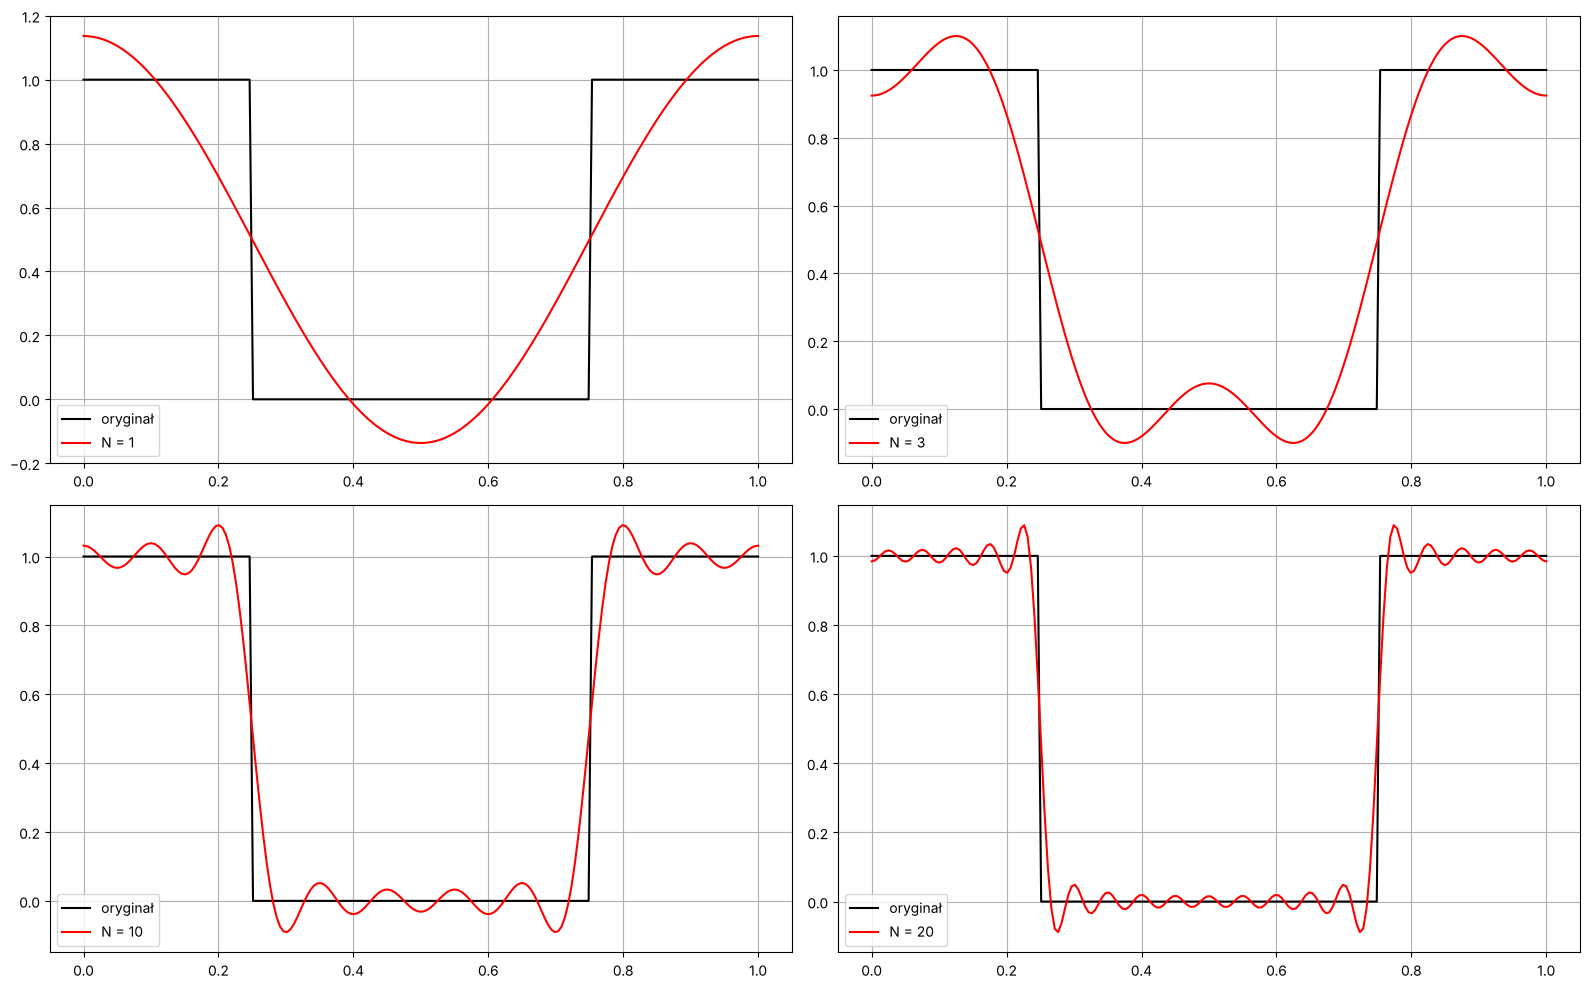

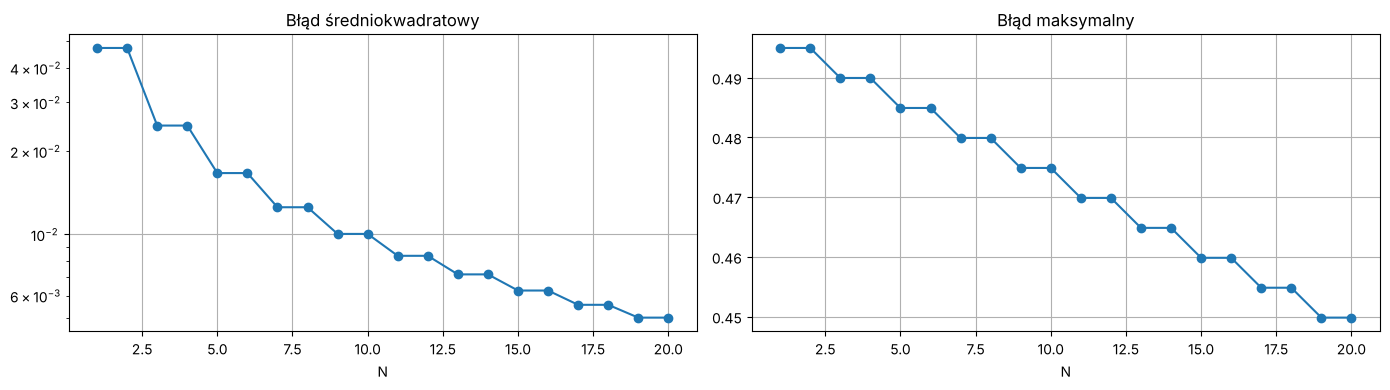

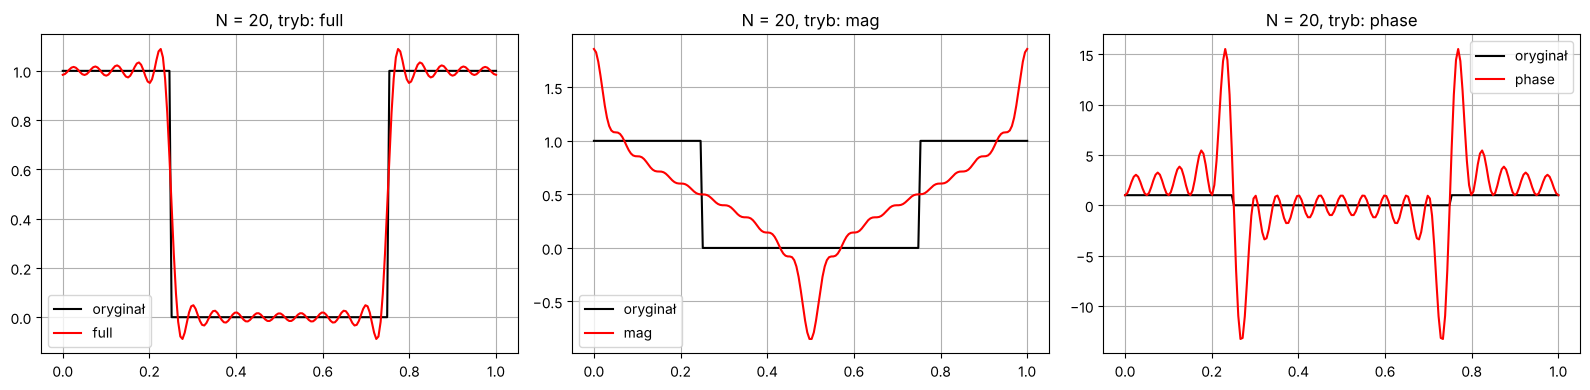

In [7]:
def complexFourierSeries(F0, Fk, tt, N, mode='full'):
    w = 2*np.pi/T                                       # pulsacja podstawowa ω = 2π/T
    Coeffs = np.zeros(N + 1, dtype=np.cdouble)          # miejsce na F0..FN
    Coeffs[0] = complex(sympy.N(F0))                    # F0
    for n in range(1, N + 1):
        Coeffs[n] = complex(sympy.N(Fk.subs(k, n)))     # F1..FN

    if mode == 'mag':                                   # tylko amplituda: Fk → |Fk|
        Coeffs = np.abs(Coeffs).astype(np.cdouble)
    if mode == 'phase':                                 # tylko faza: Fk → e^{jφk} (|Fk| = 1)
        Coeffs = np.where(np.abs(Coeffs) > 1e-12, np.exp(1j*np.angle(Coeffs)), 0)   # zerowe zostają zerami

    y = np.full(len(tt), Coeffs[0], dtype=np.cdouble)   # zaczynamy od stałej F0
    for n in range(1, N + 1):                           # dodajemy pary wyrazów +n i -n
        y += Coeffs[n]*np.exp(1j*n*w*tt) + np.conj(Coeffs[n])*np.exp(-1j*n*w*tt)
    return y.real                                       # wynik jest rzeczywisty (urojona ≈ 0)

tt = np.linspace(0, T, NumberOfSamples)                 # oś czasu

# --- rekonstrukcja dla N = 1, 3, 10, 20 ---
plt.figure(figsize=FigSize)
for i, N in enumerate([1, 3, 10, 20]):                  # i – numer wykresu, N – liczba wyrazów
    plt.subplot(2, 2, i + 1)
    plt.plot(tt, Samples, 'k', label='oryginał')        # czarny – oryginał
    plt.plot(tt, complexFourierSeries(F0, Fk, tt, N), 'r', label=f'N = {N}')   # czerwony – suma częściowa
    plt.legend()
    plt.grid()
plt.tight_layout()
plt.show()

# --- błąd średniokwadratowy i maksymalny w funkcji N ---
Ns = range(1, MaxNumCoeffs + 1)                         # N = 1..20
MSE = []                                                # listy na wyniki
MAX = []
for N in Ns:
    blad = Samples - complexFourierSeries(F0, Fk, tt, N)   # różnica oryginał – przybliżenie
    MSE.append(np.mean(blad**2))                        # błąd średniokwadratowy
    MAX.append(np.max(np.abs(blad)))                    # błąd maksymalny

plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
plt.semilogy(Ns, MSE, 'o-')                             # oś y logarytmiczna
plt.title('Błąd średniokwadratowy')
plt.xlabel('N')
plt.grid()
plt.subplot(1, 2, 2)
plt.plot(Ns, MAX, 'o-')
plt.title('Błąd maksymalny')
plt.xlabel('N')
plt.grid()
plt.tight_layout()
plt.show()

# --- tylko amplituda / tylko faza ---
plt.figure(figsize=(16, 4))
for i, mode in enumerate(['full', 'mag', 'phase']):
    plt.subplot(1, 3, i + 1)
    plt.plot(tt, Samples, 'k', label='oryginał')
    plt.plot(tt, complexFourierSeries(F0, Fk, tt, MaxNumCoeffs, mode), 'r', label=mode)
    plt.title(f'N = {MaxNumCoeffs}, tryb: {mode}')
    plt.legend()
    plt.grid()
plt.tight_layout()
plt.show()

### ✅ Wnioski / odpowiedzi na pytania

- **Zbieżność:** wraz ze wzrostem $N$ przybliżenie coraz lepiej pokrywa się z oryginałem; **MSE maleje** (prawie liniowo w skali log).
- **Efekt Gibbsa:** przy skokach funkcji D zostają „uszy” – przerzut ok. 9% wysokości skoku. Przy większym $N$ są węższe, ale **tak samo wysokie**.
- **Błąd maksymalny nie maleje do zera** – ok. 0,5, bo w samym punkcie skoku szereg daje średnią (0,5), a oryginał 0 lub 1. Szereg jest zbieżny średniokwadratowo, ale **nie jednostajnie**.
- Dla funkcji **ciągłych** (C – trójkąt, E) zbieżność jest dużo szybsza i bez Gibbsa (zmień `currFun` i sprawdź).
- **Tylko amplituda (`mag`):** kształt zupełnie inny niż oryginał – utrata informacji o fazie (dla D: o znakach współczynników) niszczy sygnał.
- **Tylko faza (`phase`):** amplitudy wszystkich harmonicznych równe 1 → ostre szpilki, ale **dokładnie w miejscach skoków** oryginału. **Faza niesie informację o położeniu w czasie** charakterystycznych punktów sygnału, amplituda – o tym, „ile” jest danej częstotliwości.

----
## 6. Zadania dodatkowe
----
### Zadanie 6.1
Dla wyznaczonych funkcji z zadania 1 wyznacz wyrażenia na współczynniki zespolonego szeregu Fouriera w sposób analityczny i porównaj wyniki. 

### Zadanie 6.2
Wykonaj polecenia z zadań C, D i E dla trygonometrycznego szeregu Fouriera (wzory z wykładu/literatury). Zmodyfikuj funkcję $complexFourierSeries$ lub zbuduj na jej podstawię funkcję rekonstruującą sygnał na podstawie podanych wyrażeń na współczynniki a1, ak i bk. Porównaj otrzymane aproksymacje dla trygonometrycznego i zespolonego szeregu Fouriera. 

### Rozwiązanie 6.1 – współczynniki wyliczone ręcznie ($T=1$, $\omega=2\pi$, $k\ge1$)

Przydatne: $e^{-j2\pi k}=1$, $e^{-j\pi k}=(-1)^k$, $\int_0^1 e^{-j2\pi kt}dt=0$, a całkę $\int t\,e^{-jat}dt$ liczymy przez części:
$$\int t\,e^{-jat}dt=e^{-jat}\left(\frac{jt}{a}+\frac{1}{a^2}\right)$$

**Przykład B** (krok po kroku):
$$F_k=\int_0^1(1-2t)e^{-j2\pi kt}dt=\underbrace{\int_0^1 e^{-j2\pi kt}dt}_{=0}-2\int_0^1 t\,e^{-j2\pi kt}dt$$
$$\int_0^1 t\,e^{-j2\pi kt}dt=\left[e^{-j2\pi kt}\left(\frac{jt}{2\pi k}+\frac{1}{4\pi^2k^2}\right)\right]_0^1=\frac{j}{2\pi k}+\frac{1}{4\pi^2k^2}-\frac{1}{4\pi^2k^2}=\frac{j}{2\pi k}$$
$$\Rightarrow F_k=-\frac{j}{\pi k}$$

**Przykład D:** drugi kawałek $[\frac34, 1)$ przesuwamy o okres do $[-\frac14, 0)$:
$$F_k=\int_{-1/4}^{1/4}e^{-j2\pi kt}dt=\frac{\sin(\pi k/2)}{\pi k}$$

**Wszystkie wyniki:**

| | $F_0$ | $F_k$ |
|---|---|---|
| A | $0$ | $-\dfrac{2+j\pi k}{\pi^2k^2}$ dla $k$ nieparzystych, $0$ dla parzystych |
| B | $0$ | $-\dfrac{j}{\pi k}$ |
| C | $\frac12$ | $-\dfrac{2}{\pi^2k^2}$ dla $k$ nieparzystych, $0$ dla parzystych |
| D | $\frac12$ | $\dfrac{\sin(\pi k/2)}{\pi k}$ |
| E | $\frac1\pi$ | $F_1=-\frac{j}{4}$; $\ -\dfrac{1}{\pi(k^2-1)}$ dla $k$ parzystych; $0$ dla nieparzystych $k\ge3$ |
| F | $1-e^{-1}$ | $\dfrac{1-e^{-1}}{1+j2\pi k}$ |

In [8]:
pi = np.pi                                           # skrót

def tylkoNieparzyste(n, wartosc):                    # pomocnicza: wartość dla n nieparzystych, 0 dla parzystych
    if n % 2 == 1:                                   # % to reszta z dzielenia → n nieparzyste
        return wartosc
    return 0

# wzory ręczne: nazwa → (F0, funkcja licząca Fk dla danego n)
Reczne = {
 'A': (0,      lambda n: tylkoNieparzyste(n, -(2 + 1j*pi*n)/(pi**2*n**2))),
 'B': (0,      lambda n: -1j/(pi*n)),
 'C': (0.5,    lambda n: tylkoNieparzyste(n, -2/(pi**2*n**2))),
 'D': (0.5,    lambda n: np.sin(pi*n/2)/(pi*n)),
 'E': (1/pi,   lambda n: -0.25j if n == 1 else (-1/(pi*(n**2-1)) if n % 2 == 0 else 0)),
 'F': (1-np.exp(-1), lambda n: (1-np.exp(-1))/(1 + 2j*pi*n)),
}

for nazwa, fun in AllFuns.items():                   # dla każdej funkcji A..F
    F0s, Fks = determineFourierCoefficients(fun, 0, T, DisplayCoeffs=False)   # wynik sympy
    sympyWyn = [complex(sympy.N(F0s))] + [complex(sympy.N(Fks.subs(k, n))) for n in range(1, 11)]
    F0r, Fkr = Reczne[nazwa]                         # wzory ręczne
    reczneWyn = [F0r] + [Fkr(n) for n in range(1, 11)]
    roznica = np.max(np.abs(np.array(sympyWyn) - np.array(reczneWyn)))      # największa różnica
    print(f'{nazwa}: max |sympy - ręcznie| = {roznica:.1e}')

A: max |sympy - ręcznie| = 6.9e-18
B: max |sympy - ręcznie| = 1.4e-17
C: max |sympy - ręcznie| = 4.3e-19


D: max |sympy - ręcznie| = 1.9e-17


E: max |sympy - ręcznie| = 1.4e-17


F: max |sympy - ręcznie| = 6.9e-18


### 🔧 Składnia – użyte funkcje

- `lambda n: wyrażenie` – **mini-funkcja w jednej linijce** (bez `def`). `lambda n: -1j/(pi*n)` to to samo co `def f(n): return -1j/(pi*n)`.
- `a if warunek else b` – **if w jednej linijce**: daje `a`, gdy warunek prawdziwy, w przeciwnym razie `b`.
- `n % 2` – reszta z dzielenia przez 2 (0 → parzyste, 1 → nieparzyste).

### 💡 Wyjaśnienie wyniku

Różnice są rzędu $10^{-17}$, czyli zero z dokładnością do błędów zaokrągleń – **wzory ręczne zgadzają się z sympy**.

### Rozwiązanie 6.2 – trygonometryczny szereg Fouriera (funkcje C, D, E)

$$f(t)=\frac{a_0}{2}+\sum_{k=1}^{\infty}\big(a_k\cos k\omega t+b_k\sin k\omega t\big)$$
$$a_0=\frac2T\int_0^T f\,dt,\qquad a_k=\frac2T\int_0^T f\cos(k\omega t)\,dt,\qquad b_k=\frac2T\int_0^T f\sin(k\omega t)\,dt$$

**Związek z szeregiem zespolonym** (z wzoru Eulera $e^{jx}=\cos x+j\sin x$):
$$a_0=2F_0,\qquad a_k=2\,\mathrm{Re}\,F_k,\qquad b_k=-2\,\mathrm{Im}\,F_k$$

--- C:  a0 = 1.00000000000000,   ak = 2.0*((-1)**k - 1)/(pi**2*k**2),   bk = 0
    max różnica trygonometryczny – zespolony: 0.0


--- D:  a0 = 1.00000000000000,   ak = 1.0*(sin(pi*k/2) - sin(3*pi*k/2))/(pi*k),   bk = 1.0*(-cos(pi*k/2) + cos(3*pi*k/2))/(pi*k)
    max różnica trygonometryczny – zespolony: 0.0


--- E:  a0 = 2.0/pi,   ak = Piecewise((1.0*((-1)**(k + 1) - 1)/(pi*(k**2 - 1)), k > 1), (0, True)),   bk = Piecewise((0, k > 1), (0.5, True))


    max różnica trygonometryczny – zespolony: 0.0


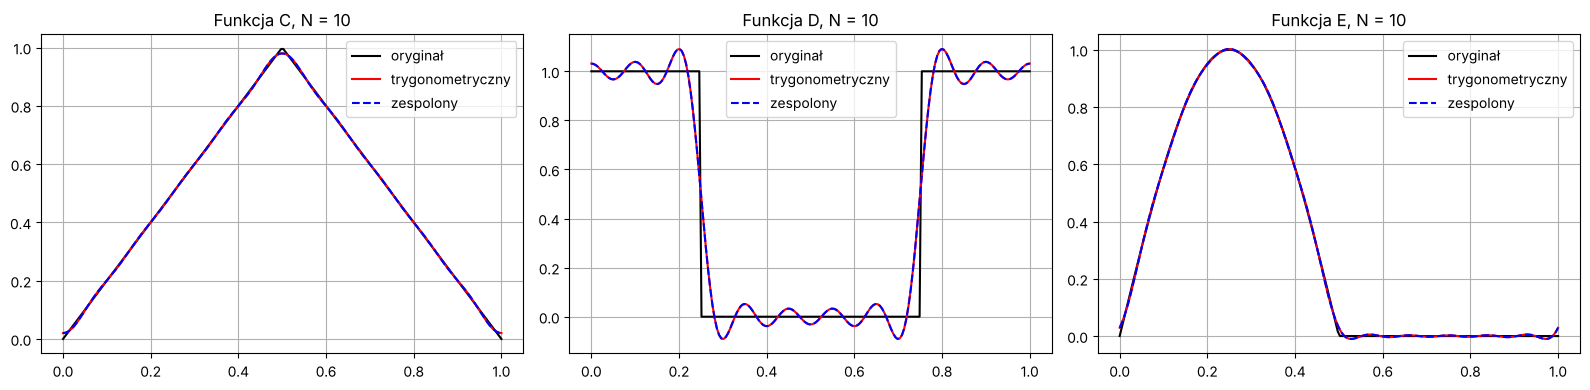

In [9]:
def determineTrigCoefficients(Function, RangeBeg, RangeEnd):
    w = 2*sympy.pi/T                                                                   # ω symbolicznie
    a0 = sympy.simplify(2/T*sympy.integrate(Function, (t, RangeBeg, RangeEnd)))                   # a0
    ak = sympy.simplify(2/T*sympy.integrate(Function*sympy.cos(k*w*t), (t, RangeBeg, RangeEnd)))  # ak
    bk = sympy.simplify(2/T*sympy.integrate(Function*sympy.sin(k*w*t), (t, RangeBeg, RangeEnd)))  # bk
    return a0, ak, bk

def trigFourierSeries(a0, ak, bk, tt, N):
    w = 2*np.pi/T                                                    # ω numerycznie
    y = np.full(len(tt), float(a0)/2)                                # stała a0/2
    for n in range(1, N + 1):
        an = float(sympy.N(ak.subs(k, n)))                           # a_n jako liczba
        bn = float(sympy.N(bk.subs(k, n)))                           # b_n jako liczba
        y += an*np.cos(n*w*tt) + bn*np.sin(n*w*tt)                   # dodajemy n-tą harmoniczną
    return y

N = 10                                                               # liczba wyrazów
plt.figure(figsize=(16, 4))
for i, nazwa in enumerate(['C', 'D', 'E']):
    fun = AllFuns[nazwa]
    a0, ak, bk = determineTrigCoefficients(fun, 0, T)
    print(f'--- {nazwa}:  a0 = {a0},   ak = {ak},   bk = {bk}')
    F0n, Fkn = determineFourierCoefficients(fun, 0, T, DisplayCoeffs=False)
    f = sympy.lambdify(t, fun, 'numpy')
    yTrig = trigFourierSeries(a0, ak, bk, tt, N)                     # szereg trygonometryczny
    yZesp = complexFourierSeries(F0n, Fkn, tt, N)                    # szereg zespolony
    print('    max różnica trygonometryczny – zespolony:', np.max(np.abs(yTrig - yZesp)))

    plt.subplot(1, 3, i + 1)
    plt.plot(tt, [f(x) for x in tt], 'k', label='oryginał')
    plt.plot(tt, yTrig, 'r', label='trygonometryczny')
    plt.plot(tt, yZesp, 'b--', label='zespolony')
    plt.title(f'Funkcja {nazwa}, N = {N}')
    plt.legend()
    plt.grid()
plt.tight_layout()
plt.show()

### ✅ Wnioski / odpowiedzi na pytania

- Oba szeregi dają **identyczne** przybliżenia (różnica ≈ 0) – to ten sam szereg zapisany na dwa sposoby, bo $F_ke^{jk\omega t}+F_k^*e^{-jk\omega t}=a_k\cos k\omega t+b_k\sin k\omega t$.
- **C** (trójkąt): tylko $a_k$ dla nieparzystych $k$, $b_k=0$; szybka zbieżność $\sim\frac{1}{k^2}$, brak Gibbsa.
- **D** (prostokąt): tylko $a_k$, $b_k=0$; zbieżność $\sim\frac1k$, widoczny Gibbs.
- **E**: $b_1=\frac12$ (połowa oryginalnej sinusoidy), reszta to $a_k$ dla parzystych $k$.
- Zapis zespolony: jedna całka zamiast dwóch, wygodny w obliczeniach. Trygonometryczny: od razu widać składowe cos i sin.

---
# 🎓 Kolokwium – przykładowe pytania z rozwiązaniami
Pytania oznaczone **[z kolokwium]** to prawdziwe przykłady od prowadzącego, pozostałe są **wymyślone w tym samym stylu**. Przy każdym:
- **Odpowiedź (do wpisania)** – krótki tekst, który można wpisać w pole odpowiedzi,
- **Jak to rozwiązać** – kroki, żeby umieć zrobić podobne zadanie samemu,
- kod tam, gdzie zadanie wymaga obliczeń lub wykresu (na kolokwium można dołączyć zrzut wykresu jako obrazek).

### Pytanie 1 [z kolokwium]
**Na czym polega efekt Gibbsa? Krótko wyjaśnij.**

**Odpowiedź (do wpisania):**
Efekt Gibbsa występuje przy przybliżaniu sygnału z **nieciągłością (skokiem)** skończoną sumą wyrazów szeregu Fouriera. W pobliżu skoku suma częściowa **oscyluje i przestrzeliwuje** wartość sygnału o ok. **9% wysokości skoku**. Zwiększanie liczby wyrazów $N$ sprawia, że oscylacje stają się węższe i zbliżają się do punktu skoku, ale **ich amplituda nie maleje**. Oznacza to, że szereg jest zbieżny średniokwadratowo (błąd MSE → 0), ale nie jednostajnie (błąd maksymalny nie dąży do zera). W samym punkcie skoku szereg zbiega do średniej $\frac{f(t^-)+f(t^+)}{2}$.

**Jak to zapamiętać:** skok → „uszy” na wykresie rekonstrukcji, ~9%, nie znikają przy większym N (patrz wykresy funkcji D w zadaniu 5).

### Pytanie 2 (teoria)
Jakie założenia musi spełniać funkcja, żeby można ją było rozwinąć w szereg Fouriera?

**Odpowiedź (do wpisania):** funkcja musi być **okresowa** z okresem $T$ i spełniać **warunki Dirichleta**: bezwzględnie całkowalna na okresie, skończona liczba ekstremów i skończona liczba nieciągłości pierwszego rodzaju w okresie. Wtedy szereg zbiega do $f(t)$ w punktach ciągłości, a w punktach skoku do średniej granic jednostronnych.

### Pytanie 3
Wyznacz współczynniki zespolonego szeregu Fouriera funkcji $f(t)=t$ dla $t\in[0,1)$, $T=1$ (piła rosnąca).

**Jak to rozwiązać:**
1. $F_0=\frac1T\int_0^T f\,dt=\int_0^1 t\,dt=\frac12$.
2. $F_k=\int_0^1 t\,e^{-j2\pi kt}\,dt$ – całka przez części albo `sympy.integrate`.
3. Pamiętaj o `k` jako `integer=True, positive=True`, żeby sympy uprościł $e^{-j2\pi k}=1$.

**Odpowiedź (do wpisania):** $F_0=\frac12$, $\ F_k=\dfrac{j}{2\pi k}$ (czysto urojone, $|F_k|\sim\frac1k$ – bo funkcja ma skok na granicy okresu).

In [10]:
fPila = t                                                        # f(t) = t na [0, 1)
F0p, Fkp = determineFourierCoefficients(fPila, 0, T)             # F0 = 1/2, Fk = j/(2πk)

'F0 ='

0.500000000000000

'Fk ='

0.5*I/(pi*k)

### Pytanie 4 (teoria)
Co mówi o sygnale moduł $|F_k|$, a co faza $\arg F_k$? Dlaczego dla sygnału rzeczywistego wystarczy liczyć $F_k$ dla $k>0$?

**Odpowiedź (do wpisania):** $|F_k|$ to amplituda $k$-tej harmonicznej (ile jest w sygnale składowej o pulsacji $k\omega$), $\arg F_k$ to jej przesunięcie fazowe – faza decyduje o położeniu w czasie charakterystycznych punktów sygnału (np. skoków). Dla sygnału rzeczywistego $F_{-k}=F_k^*$, więc współczynniki ujemne są sprzężeniem dodatnich i nie trzeba ich liczyć osobno.

### Pytanie 5
Po czym poznać z samych współczynników, że sygnał ma nieciągłość?

**Odpowiedź (do wpisania):** współczynniki maleją wolno, jak $\frac1k$ (np. prostokąt, piła). Dla sygnału ciągłego z „załamaniem” (trójkąt) maleją jak $\frac1{k^2}$, dla gładkiego jeszcze szybciej. Wolne malenie oznacza też efekt Gibbsa przy rekonstrukcji.

---
## 📝 Ściąga – Laboratorium 3

**Wzory**
$$f(t)=\sum_{k=-\infty}^{\infty}F_ke^{jk\omega t},\quad \omega=\frac{2\pi}{T},\quad F_k=\frac1T\int_0^T f(t)e^{-jk\omega t}dt,\quad F_0=\frac1T\int_0^Tf\,dt$$
$$F_{-k}=F_k^*,\qquad a_0=2F_0,\ a_k=2\mathrm{Re}F_k,\ b_k=-2\mathrm{Im}F_k$$

**Własności:** skok → $|F_k|\sim\frac1k$ + efekt Gibbsa (~9%); funkcja ciągła z „załamaniem” → $\sim\frac1{k^2}$; funkcja parzysta → $F_k$ rzeczywiste; nieparzysta → urojone.

**sympy**
| | |
|---|---|
| `sympy.Piecewise((w1, war1), (w2, True))` | funkcja przedziałami |
| `sympy.lambdify(t, wyr, 'numpy')` | wzór → funkcja Pythona |
| `sympy.integrate(f, (t, a, b))` | całka oznaczona |
| `sympy.exp, sympy.sin, sympy.pi, sympy.I` | funkcje i stałe symboliczne |
| `wyr.subs(k, 3)`, `sympy.N(wyr)` | podstawienie, wartość liczbowa |
| `Symbol('k', integer=True, positive=True)` | założenia upraszczające wynik |

**numpy**
| | |
|---|---|
| `np.zeros(n, dtype=np.cdouble)` | wektor zespolony |
| `1j`, `np.exp(1j*x)` | jednostka urojona, $e^{jx}$ |
| `np.abs, np.angle, np.conj, .real, .imag` | moduł, faza, sprzężenie, części |

**Python:** `[f(x) for x in tt]` (list comprehension), `lambda n: ...`, `a if war else b`, `słownik.items()`, `try: ... except ImportError: ...`.